# Laboratorium 3 - 28.10.2026

### Przygotowanie środowiska

In [5]:
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

def stan(theta_deg, phi_deg):
    t, f = np.radians([theta_deg, phi_deg])
    return np.array([np.cos(t/2), np.exp(1j*f)*np.sin(t/2)])

def bloch(psi):
    a, b = psi
    return np.array([2*np.real(np.conj(a)*b),
                    2*np.imag(np.conj(a)*b),
                    abs(a)**2-abs(b)**2])

def pokaz(psi, tytul="Stan qubitu"):
    x, y, z = bloch(psi)
    print("Amplitudy:", np.round(psi, 4))
    print("P(0), P(1):", np.round(np.abs(psi)**2, 4))
    print("x, y, z:", np.round([x, y, z], 4))
    fig = plt.figure(figsize=(6, 5))
    ax = fig.add_subplot(111, projection="3d")
    u = np.linspace(0, 2*np.pi, 32)
    v = np.linspace(0, np.pi, 17)
    ax.plot_wireframe(np.outer(np.cos(u), np.sin(v)),
                      np.outer(np.sin(u), np.sin(v)),
                      np.outer(np.ones_like(u),np.cos(v)),
                      color="lightgray", linewidth=0.4)
    for e in np.eye(3):
        ax.plot(*np.array([-e, e]).T, color="gray", lw=0.7)
    ax.quiver(0, 0, 0, x, y, z, color="red",
              arrow_length_ratio=0.12, linewidth=2)
    ax.text(0, 0, 1.12, "|0>")
    ax.text(0, 0, -1.18, "|1>")
    ax.set(xlim=(-1.2, 1.2), ylim=(-1.2, 1.2),
          zlim=(-1.2, 1.2), xlabel="x", ylabel="y",
          zlabel="z", title=tytul)
    ax.set_box_aspect((1, 1, 1))
    display(fig)
    plt.close(fig)

Amplitudy: [0.866+0.j  0.   +0.5j]
P(0), P(1): [0.75 0.25]
x, y, z: [0.    0.866 0.5  ]


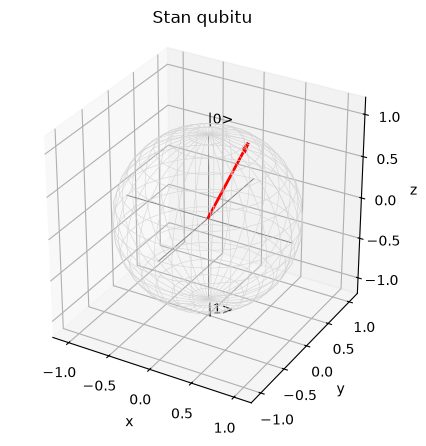

In [2]:
pokaz(stan(60,90))

### Zadanie 1 - Szcześć różnych stanów

Amplitudy: [1.+0.j 0.+0.j]
P(0), P(1): [1. 0.]
x, y, z: [0. 0. 1.]


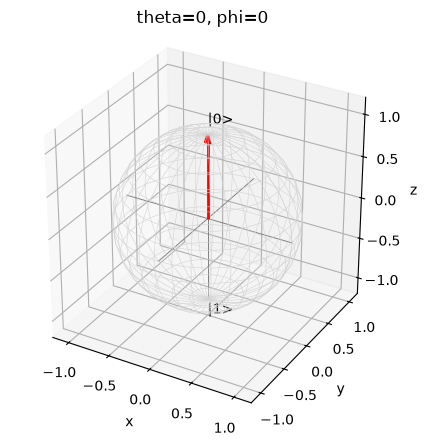

Amplitudy: [0.+0.j 1.+0.j]
P(0), P(1): [0. 1.]
x, y, z: [ 0.  0. -1.]


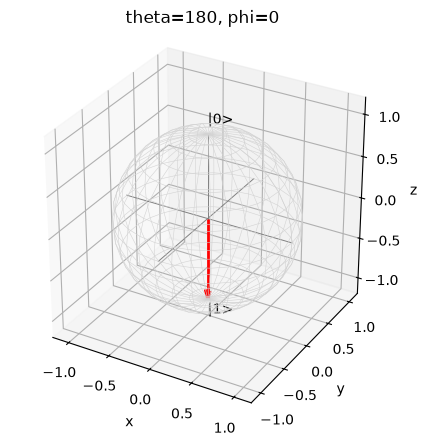

Amplitudy: [0.7071+0.j 0.7071+0.j]
P(0), P(1): [0.5 0.5]
x, y, z: [1. 0. 0.]


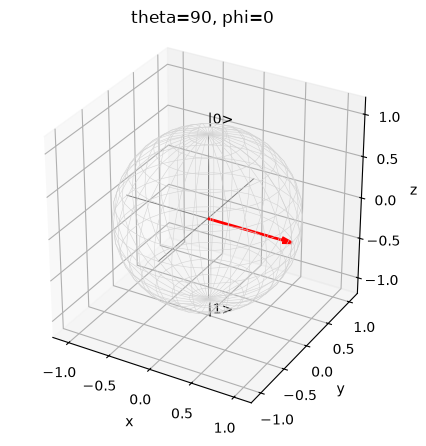

Amplitudy: [ 0.7071+0.j -0.7071+0.j]
P(0), P(1): [0.5 0.5]
x, y, z: [-1.  0.  0.]


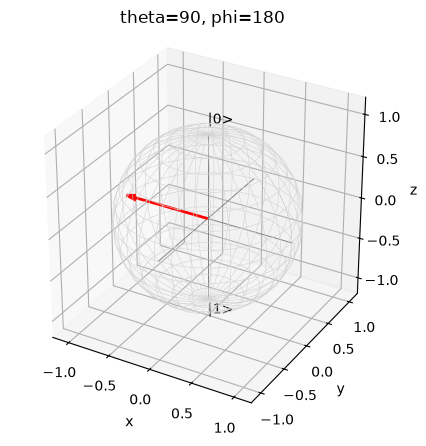

Amplitudy: [0.7071+0.j     0.    +0.7071j]
P(0), P(1): [0.5 0.5]
x, y, z: [0. 1. 0.]


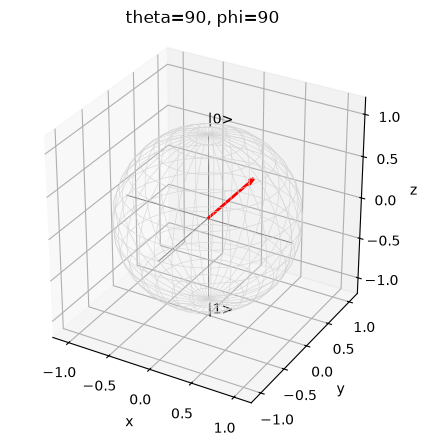

Amplitudy: [ 0.7071+0.j     -0.    -0.7071j]
P(0), P(1): [0.5 0.5]
x, y, z: [-0. -1.  0.]


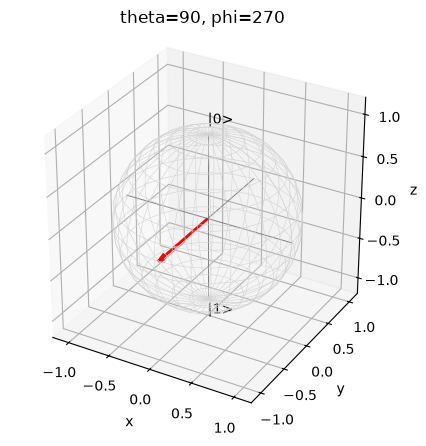

In [6]:
przypadki = [(0, 0),
            (180, 0),
            (90, 0),
            (90, 180),
            (90, 90),
            (90, 270)]
for (theta, phi) in przypadki:
    psi = stan(theta, phi)
    pokaz(psi, f"theta={theta}, phi={phi}")


| $\theta$ [$^\circ$] | $\phi$ [$^\circ$] | Stan | (x, y, z) | P(0), P(1) |
| :---: | :---: | :---: | :---: | :---: |
| 0 | 0 | $\|0\rangle$ | (0.0, 0.0, 1.0) | 1.0, 0.0 |
| 180 | 0 | $\|1\rangle$ | (0.0, 0.0, -1.0) | 0.0, 1.0 |
| 90 | 0 | $\|+\rangle$ | (1.0, 0.0, 0.0) | 0.5, 0.5 |
| 90 | 180 | $\|-\rangle$ | (-1.0, 0.0, 0.0) | 0.5, 0.5 |
| 90 | 90 | $\|{+i}\rangle$ | (0.0, 1.0, 0.0) | 0.5, 0.5 |
| 90 | 270 | $\|{-i}\rangle$ | (0.0, -1.0, 0.0) | 0.5, 0.5 |

Wniosek: Pary leżące na przeciwległych końcach tej samej osi to: |0> i |1> (oś z), |+> i |-> (oś x) oraz |+i> i |-i> (oś y). Wszystkie stany leżące na theta = 90 mają takie same prawdopodobieństwa (P(0) = P(1) = 0.5)

### Zadanie 2 - Kąt biegunowy i prawdopodobieństwa

Amplitudy: [1.+0.j 0.+0.j]
P(0), P(1): [1. 0.]
x, y, z: [0. 0. 1.]


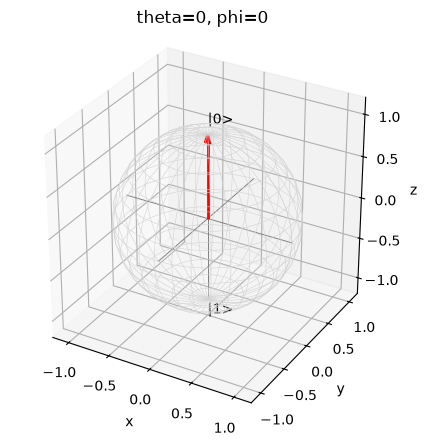

Amplitudy: [0.866+0.j 0.5  +0.j]
P(0), P(1): [0.75 0.25]
x, y, z: [0.866 0.    0.5  ]


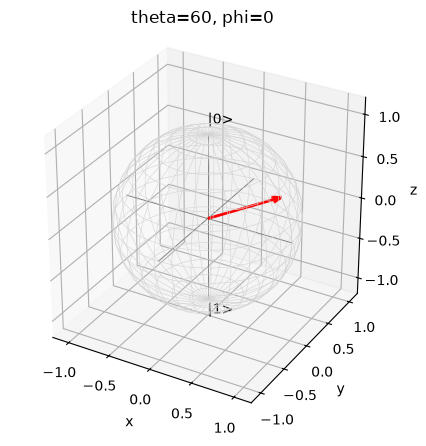

Amplitudy: [0.7071+0.j 0.7071+0.j]
P(0), P(1): [0.5 0.5]
x, y, z: [1. 0. 0.]


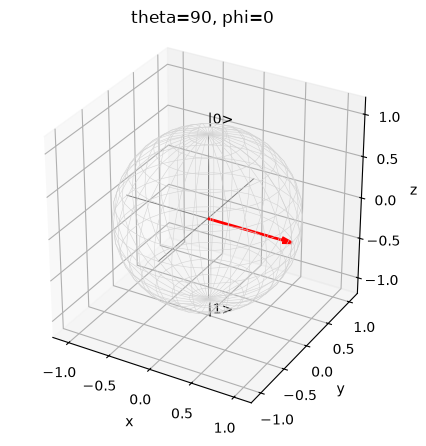

Amplitudy: [0.5  +0.j 0.866+0.j]
P(0), P(1): [0.25 0.75]
x, y, z: [ 0.866  0.    -0.5  ]


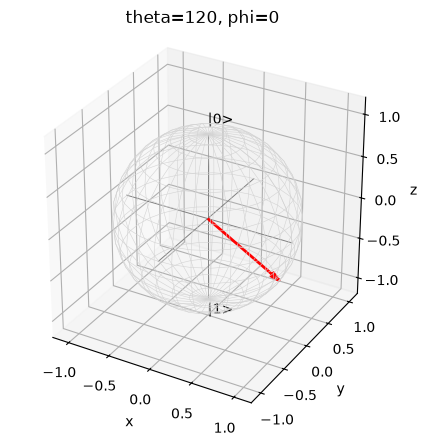

Amplitudy: [0.+0.j 1.+0.j]
P(0), P(1): [0. 1.]
x, y, z: [ 0.  0. -1.]


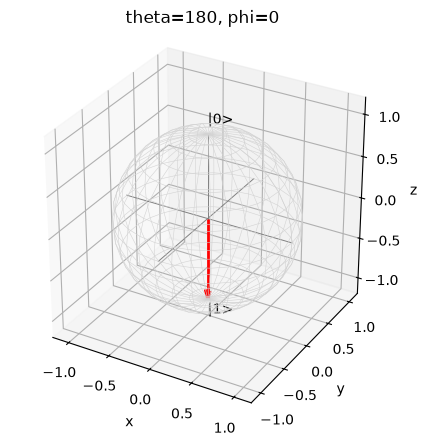

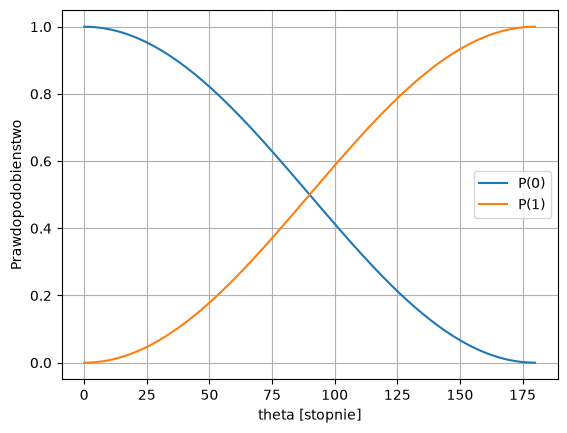

In [7]:
phi = 0
for theta in [0, 60, 90, 120, 180]:
    psi = stan(theta, phi)
    pokaz(psi, f"theta={theta}, phi=0")
katy = np.arange(0, 181)
t = np.radians(katy)
p0 = np.cos(t/2)**2
p1 = np.sin(t/2)**2
plt.plot(katy, p0, label="P(0)")
plt.plot(katy, p1, label="P(1)")
plt.xlabel("theta [stopnie]")
plt.ylabel("Prawdopodobienstwo")
plt.legend()
plt.grid()
plt.show()

| $\theta$ [$^\circ$] | P(0) | z | P(1) |
| :---: | :---: | :---: | :---: |
| 0 | 1.0 | 1.0 | 0.0 |
| 60 | 0.75 | 0.5 | 0.25 |
| 90 | 0.5 | 0.0 | 0.5 |
| 120 | 0.25 | -0.5 | 0.75 |
| 180 | 0.0 | -1.0 | 1.0 |

Wniosek: Gdy kąt biegunowy rośnie od 0 do 180 stopni, punkt porusza się od bieguna północnego do południowego, co skutkuje spadkiem wartości z z 1 do -1. Prawdopodobieństwo P(0) maleje z 1 do 0 (oba wyniki są jednakowo prawdopodobne dla kąta $\theta = 90^\circ$).

### Zadanie 3 - Kąt fazowy i ruch po równiku

phi, P(+): 0 1.0
Kontrola P(+): 1.0
Amplitudy: [0.7071+0.j 0.7071+0.j]
P(0), P(1): [0.5 0.5]
x, y, z: [1. 0. 0.]


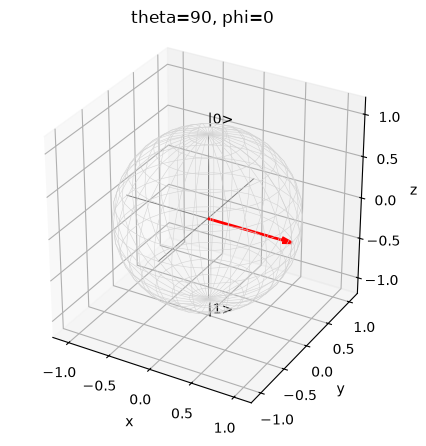

phi, P(+): 90 0.7071
Kontrola P(+): 0.5
Amplitudy: [0.7071+0.j     0.    +0.7071j]
P(0), P(1): [0.5 0.5]
x, y, z: [0. 1. 0.]


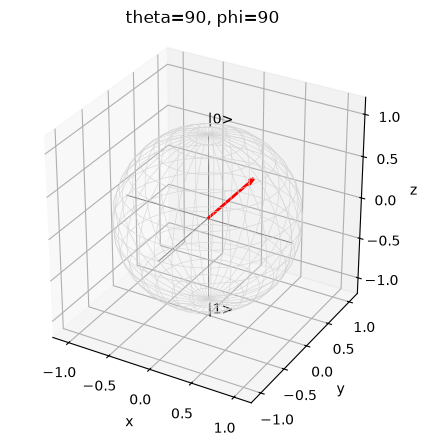

phi, P(+): 180 0.0
Kontrola P(+): -0.0
Amplitudy: [ 0.7071+0.j -0.7071+0.j]
P(0), P(1): [0.5 0.5]
x, y, z: [-1.  0.  0.]


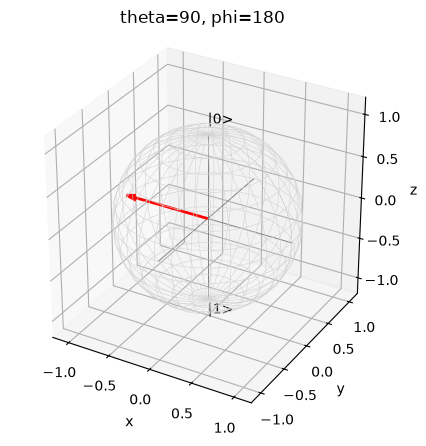

phi, P(+): 270 0.7071
Kontrola P(+): 0.5
Amplitudy: [ 0.7071+0.j     -0.    -0.7071j]
P(0), P(1): [0.5 0.5]
x, y, z: [-0. -1.  0.]


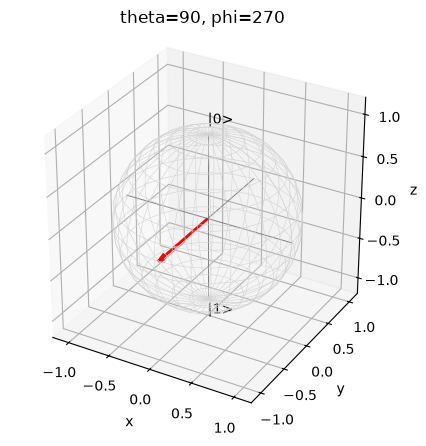

phi, P(+): 0 0.9659
Kontrola P(+): 0.933
Amplitudy: [0.866+0.j 0.5  +0.j]
P(0), P(1): [0.75 0.25]
x, y, z: [0.866 0.    0.5  ]


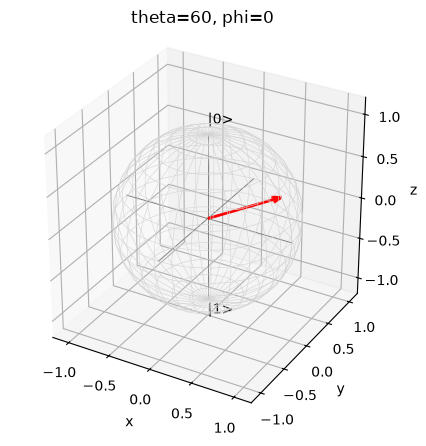

phi, P(+): 90 0.7071
Kontrola P(+): 0.5
Amplitudy: [0.866+0.j  0.   +0.5j]
P(0), P(1): [0.75 0.25]
x, y, z: [0.    0.866 0.5  ]


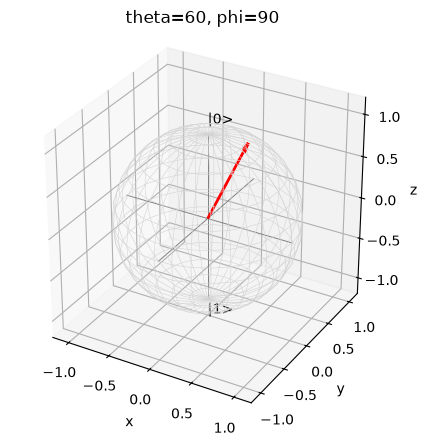

phi, P(+): 180 0.2588
Kontrola P(+): 0.067
Amplitudy: [ 0.866+0.j -0.5  +0.j]
P(0), P(1): [0.75 0.25]
x, y, z: [-0.866  0.     0.5  ]


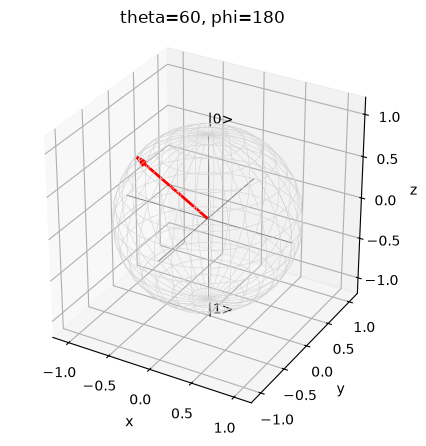

phi, P(+): 270 0.7071
Kontrola P(+): 0.5
Amplitudy: [ 0.866+0.j  -0.   -0.5j]
P(0), P(1): [0.75 0.25]
x, y, z: [-0.    -0.866  0.5  ]


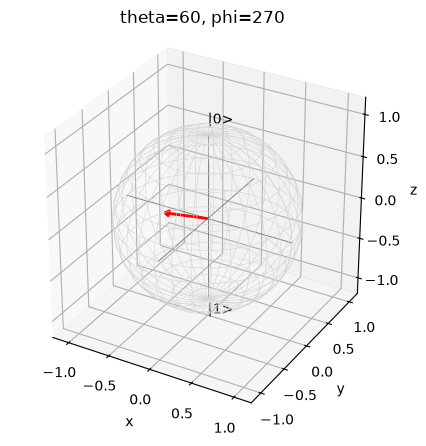

In [8]:
theta = [90,60]
plus = np.array([1, 1])/np.sqrt(2)
for t in theta:
    for phi in [0, 90, 180, 270]:
        psi = stan(t, phi)
        r = bloch(psi)
        p_plus = np.round(abs(np.vdot(plus, psi)), 4)
        print("phi, P(+):", phi, p_plus)
        print("Kontrola P(+):", np.round((1 + r[0])/2, 4))
        pokaz(psi, f"theta={t}, phi={phi}")

| $\phi$ [$^\circ$] | (x, y, z) dla $\theta=90^\circ$ | P(0) | P(1) | P(+) |
| :---: | :---: | :---: | :---: | :---: |
| 0 | (1.0, 0.0, 0.0) | 0.5 | 0.5 | 1.0 |
| 90 | (0.0, 1.0, 0.0) | 0.5 | 0.5 | 0.5 |
| 180 | (-1.0, 0.0, 0.0) | 0.5 | 0.5 | 0.0 |
| 270 | (0.0, -1.0, 0.0) | 0.5 | 0.5 | 0.5 |

Wniosek: Jednakowe prawdopodobieństwa w bazie Z nie definiują fizycznie tego samego stanu, ponieważ nie niosą informacji o fazie względnej. Różne wartości kąta fazowego powodują obrót na sferze wzdłuż równika, co można wykryć dokonując pomiaru w bazie X, gdzie P(+) przybiera różne wartości.

### Zadanie 4 - Faza globalna i względna

In [9]:
psi = stan(90, 0)
gamma = np.radians(180)
psi_globalna = np.exp(1j*gamma)*psi
psi_wzgledna = psi.copy()
psi_wzgledna[1] *= np.exp(1j*gamma)
plus = np.array([1, 1])/np.sqrt(2)

for nazwa, s in [("poczatkowy", psi),
                 ("globalna", psi_globalna),
                 ("wzgledna", psi_wzgledna)]:
    print(nazwa, "Bloch:", np.round(bloch(s), 4))
    print("P(0), P(1):", np.round(np.abs(s)**2, 4))
    print("P(+):", np.round(abs(np.vdot(plus, s))**2), 4)

poczatkowy Bloch: [1. 0. 0.]
P(0), P(1): [0.5 0.5]
P(+): 1.0 4
globalna Bloch: [1. 0. 0.]
P(0), P(1): [0.5 0.5]
P(+): 1.0 4
wzgledna Bloch: [-1.  0.  0.]
P(0), P(1): [0.5 0.5]
P(+): 0.0 4


Wniosek: Faza globalna nie zmienia stanu fizycznego i wektor Blocha pozostaje w tym samym miejscu. Zmiana fazy względnej obraca wektor po sferze – z tego powodu samo porównanie P(0) i P(1) jest niewystarczające, bo nie informuje o tym obrocie, który wpływa na P(+).

### Zadanie 5 - Od amplitud do kątów


Dla beta = 0.5j:
theta, phi [stopnie]: 60.0 90.0
Bloch: [0.    0.866 0.5  ]
Ten sam punkt: True
Amplitudy: [0.866+0.j  0.   +0.5j]
P(0), P(1): [0.75 0.25]
x, y, z: [0.    0.866 0.5  ]


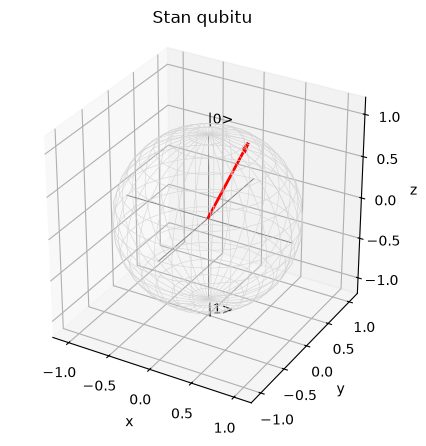


Dla beta = (-0-0.5j):
theta, phi [stopnie]: 60.0 270.0
Bloch: [-0.    -0.866  0.5  ]
Ten sam punkt: True
Amplitudy: [ 0.866+0.j  -0.   -0.5j]
P(0), P(1): [0.75 0.25]
x, y, z: [-0.    -0.866  0.5  ]


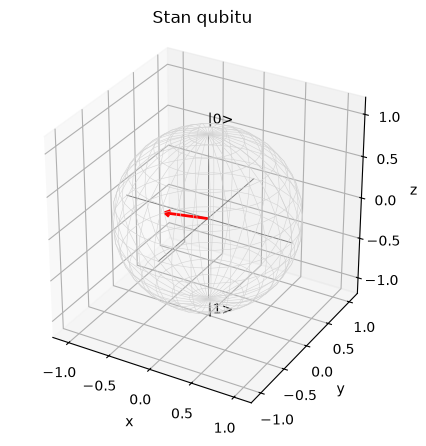

In [14]:
beta_vals = [1j/2, -1j/2]

for b_val in beta_vals:
    psi = np.array([np.sqrt(3)/2, b_val])
    a, b = psi
    theta = 2*np.arccos(np.clip(abs(a), 0, 1))
    phi = (np.angle(b)-np.angle(a)) % (2*np.pi)
    
    theta_deg = np.degrees(theta)
    phi_deg = np.degrees(phi)
    
    print(f"\nDla beta = {b_val}:")
    print("theta, phi [stopnie]:", np.round(theta_deg, 4), np.round(phi_deg, 4))
    print("Bloch:", np.round(bloch(psi), 4))
    
    odtworzony = stan(theta_deg, phi_deg)
    print("Ten sam punkt:", np.allclose(bloch(psi), bloch(odtworzony)))
    pokaz(psi)

| beta przy alfa = sqrt(3)/2 | $\theta$ [°] | $\phi$ [°] | (x, y, z) | P(0), P(1) |
| :---: | :---: | :---: | :---: | :---: |
| i/2 | 60 | 90 | (0.0, 0.866, 0.5) | 0.75, 0.25 |
| -i/2 | 60 | 270 | (0.0, -0.866, 0.5) | 0.75, 0.25 |

Wniosek: Stany nie są antypodyczne. Tutaj zmienia się wyłącznie znak współrzędnej y. Oznacza to po prostu przeciwne zwroty fazy względnej przy zachowaniu tej samej wysokości z.